In [13]:
import os
from pathlib import Path
import pandas as pd
import librosa

import numpy as np
import matplotlib.pyplot as plt
from numpy import ndarray
import random
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm
import pyworld as pw

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from IPython.display import display, Audio

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Note

We need to define two modules in the pipeline

```bash
        --------------      ----------------
wav --> | Extraction |  --> | Manipulation |  --> manipulated feat
        --------------      ----------------
```

# Common functions

In [5]:
def load_audio(audio_path):
    """
    wav, sr = load_audio(audio_path)
    
    input
    -----
      audio_path: str, path to the audio
      
    output
    ------
      wav: np.array, (channel, length)
      wav: sr, int, sampling rate
    """
    return librosa.load(audio_path, sr=None)
    

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()


In [6]:
import scipy
import scipy.signal
import numpy as np
import copy 

def plot_imshow(data, fig, axis, config_dic):
    """
    """
    plot_colorbar = False        
    if "plot_imshow" in config_dic:
        temp_dic = copy.deepcopy(config_dic["plot_imshow"])
        if "colorbar" in temp_dic:
            plot_colorbar = temp_dic['colorbar']
            temp_dic.pop("colorbar")
        pos = axis.imshow(data, **temp_dic)
    else:
        # default configuration
        pos = axis.imshow(data, cmap='jet', origin='lower', aspect='auto')
    if type(plot_colorbar) is dict:
        fig.colorbar(pos, **plot_colorbar)
    elif plot_colorbar:
        fig.colorbar(pos)
    else:
        pass
    return fig, axis
    
def _spec(data, fft_bins=4096, frame_shift=40, frame_length=240):
    f, t, cfft = scipy.signal.stft(
        data, nfft=fft_bins, 
        noverlap=frame_length-frame_shift, nperseg=frame_length)
    return f,t,cfft

def _amplitude(cfft):
    mag = np.power(np.power(np.real(cfft),2) + np.power(np.imag(cfft),2), 0.5)
    return mag

def _amplitude_to_db(mag):
    return 20*np.log10(mag+ np.finfo(np.float32).eps)

def _spec_amplitude(data, fft_bins=4096, frame_shift=40, frame_length=240):
    _, _, cfft = _spec(data, fft_bins, frame_shift, frame_length)
    mag  = _amplitude(cfft)
    return _amplitude_to_db(mag)

def plot_spec(data, fig, axis, config_dic):
    """ 
    fig, axis = plot_spec(data, fig, axis, config_dic)
    This function will plot spectrogram, given configuration in config_dic
    
    input
    -----
      data: data
      fig: fig handler
      axis: axis handler
      config_dic: configuration dictionary
    
    output
    ------
      fig: fig handler
      axis: axis handler
    """

    if type(data) is list:
        print("plot_spectrogram only supports data array input, ")
        print("but it receives list of data")
        sys.exit(1)
    
    # default configuration
    tmp_dic = copy.deepcopy(config_dic["plot_spec"]) \
              if "plot_spec" in config_dic else {}
    
    if "sampling_rate" in tmp_dic:
        sr = tmp_dic["sampling_rate"]  
        tmp_dic.pop("sampling_rate")
    else:
        sr = None
    if "frame_shift" in tmp_dic:
        fs = tmp_dic["frame_shift"]
        tmp_dic.pop("frame_shift")
    else:
        fs = 80
    if "frame_length" in tmp_dic:
        fl = tmp_dic["frame_length"]
        tmp_dic.pop("frame_length")
    else:
        fl =  320
    if "fft_bins" in tmp_dic:
        fn = tmp_dic["fft_bins"] 
        tmp_dic.pop("fft_bins")
    else:
        fn = 1024
    
    # stft
    spec = _spec_amplitude(data, fn, fs, fl)
    
    tmp_config_dic = config_dic.copy()
    if tmp_dic:
        tmp_config_dic["plot_imshow"] = tmp_dic

    plot_imshow(spec, fig, axis, tmp_config_dic)
    
    # options on label
    if "xlabel" not in config_dic:
        axis.set_xlabel("Frame index")
        
    if "ylabel" not in config_dic:
        if sr is None:
            axis.set_ylabel("Frequency bins")
        else:
            axis.set_ylabel("Frequency (Hz)")
            
    # ticks
    if "yticks" not in config_dic:            
        yticks_to_use = [(fn//2+1)//2, fn//2+1]
    else:
        yticks_to_use = config_dic["yticks"]
        config_dic.pop("yticks", None)
    
    axis.set_yticks(yticks_to_use)
    if sr is not None:
        freq_str = ["{:4.1f}".format(x * sr // 2 // 1000 / (fn//2+1)) \
                    for x in yticks_to_use]
        axis.set_yticklabels(freq_str)

    max_time = spec.shape[1] * fs / sr
    time_label = [np.floor(x) for x in np.linspace(0, max_time, 5)]
    xticks = [x * sr / fs for x in time_label]
    axis.set_xticks(xticks)
    axis.set_xticklabels(['{:.1f}'.format(x) for x in time_label])
    axis.set_xlabel('Time (s)')
    
    return fig, axis

In [28]:
# 
def pyworld_analysis(input_wav, sr, fs=5):
    # analysis
    x = np.array(input_wav, dtype=np.float64)
    _f0, t = pw.dio(x, sr, frame_period=fs)    # raw pitch extractor
    f0 = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    sp = pw.cheaptrick(x, f0, t, sr)  # extract smoothed spectrogram
    ap = pw.d4c(x, f0, t, sr)         # extract aperiodicity
    return f0, sp, ap, sr

def pyworld_synthesis(f0, sp, ap, sr, fs=5):
    # synthesis the original waveform
    y = pw.synthesize(f0, sp, ap, sr, frame_period=fs) # synthesize an utterance using the parameters
    return y

# F0 

## F0 Inconsistency
**Target system:** Concatenative TTS  
**Feature:** F0 trajectory  
**Manipulations:**
- F0 segment shifting  
- F0 segment shuffling


### extraction

In [16]:
# extraction
def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:
    """
    input
    -----
      waveform: np.array, (c, n) or (n), where c is the #. channel
      fs: int, sampling rate
      win_size: int, window size
      hop_size: int, hop size
      fmin: int, minimum of F0
      fmax: int, maximum of F0
      
    output
    ------
      f0_freqs: f0 frequency (c, n_frames), or (n_frames)
    """
    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )


    # pyworld_analysis
    #x = np.array(x, dtype=np.float64)
    #_f0, t = pw.dio(x, sr)    # raw pitch extractor
    #f0_freqs = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    
    return f0_freqs

### manipulation

In [17]:
# manipulation

def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.90, 0.95),
                    random.uniform(1.05, 1.00)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]

    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start+L] = seg[:L]

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    else:
        f0_traj_mod = None
        print(f"Manipulation not recognized.")
        
    return f0_traj_mod
    

### reconstruction (optional)

only for demonstration purpose


In [29]:
def reconstruct_wav_f0(orig_wav, f0_traj_mod, sr, period):
    # set unvoiced region to 0.0
    f0_traj_mod_ = np.zeros_like(f0_traj_mod) + f0_traj_mod
    f0_traj_mod_[f0_traj_mod_ != f0_traj_mod_] = 0.0

    # analysis
    _, sp, ap, sr = pyworld_analysis(orig_wav, sr, period)
    # re-construct
    return np.array(pyworld_synthesis(f0_traj_mod_, sp, ap, sr, period), dtype=orig_wav.dtype)
    

### demonstration

using the training portion of ASVspoof2019

In [18]:
p = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
f = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

df_all = pd.read_csv(p, sep=' ', header=None)

df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f) / f"{x}.flac"
    ))[['path']]
)

# selected_files = random.sample(df_real['path'].tolist(), 5)
selected_files = df_real['path'].tolist()

In [19]:
mod = 'shift'
fs = 16000
stft_params = STFTWindowParams()

# using a single utterance
filepath = selected_files[0]
x, sr = load_audio(filepath)

# extraction
f0_traj = extract_f0(
        x,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )


# manipulation    
f0_traj_mod = apply_f0_mod(f0_traj, mod=mod, hop_s=stft_params.hop_sec)

In [30]:
# for demonstration, show resynthesized waveform
period = stft_params.hop_size / sr * 1000
x_mod = reconstruct_wav_f0(x, f0_traj_mod, sr, period)

'Original'

'Modified'

(<Figure size 944x300 with 1 Axes>,
 <Axes: xlabel='Time (s)', ylabel='Frequency (Hz)'>)

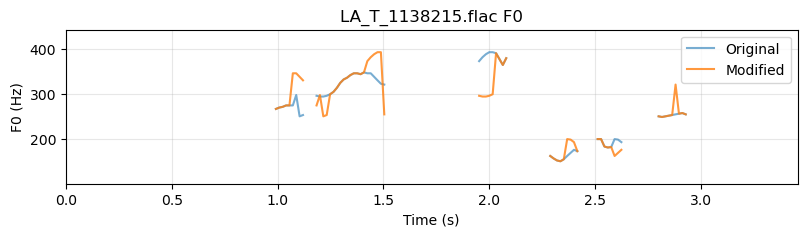

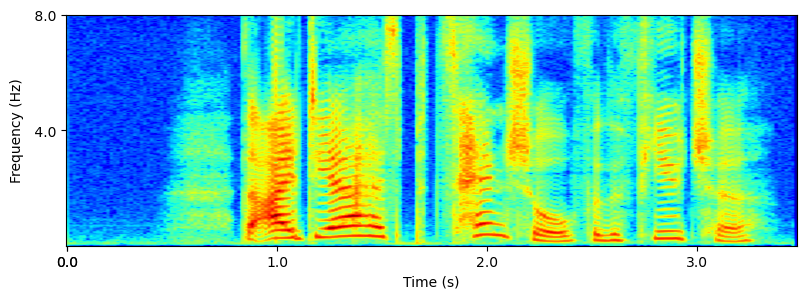

In [32]:
# plotting 
fig, axes = plt.subplots(1, 1, figsize=(9.44, 2), sharex=False)


n_frames = len(f0_traj)
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)

valid = np.isfinite(f0_traj)
f0_min = np.nanmin(f0_traj[valid])
f0_max = np.nanmax(f0_traj[valid])
pad = 50  # Hz for visualization

axes.plot(time, f0_traj, label="Original", alpha=0.6)
axes.plot(time, f0_traj_mod, label="Modified", alpha=0.8)
axes.set_title(f"{str(filepath.name)} F0")
axes.set_ylim(f0_min - pad, f0_max + pad)
axes.set_xlim(0, max(time))
axes.legend()

axes.set_xlabel("Time (s)")
axes.set_ylabel("F0 (Hz)")
axes.grid(True, alpha=0.3)

display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig, axis = plt.subplots(1, 1, figsize=(9.44, 3), sharex=False)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})


In [33]:
mod = 'shuff'

# manipulation    
f0_traj_mod = apply_f0_mod(f0_traj, mod=mod, hop_s=stft_params.hop_sec)

In [34]:
# for demonstration, show resynthesized waveform
period = stft_params.hop_size / sr * 1000
x_mod = reconstruct_wav_f0(x, f0_traj_mod, sr, period)

'Original'

'Modified'

(<Figure size 944x300 with 1 Axes>,
 <Axes: xlabel='Time (s)', ylabel='Frequency (Hz)'>)

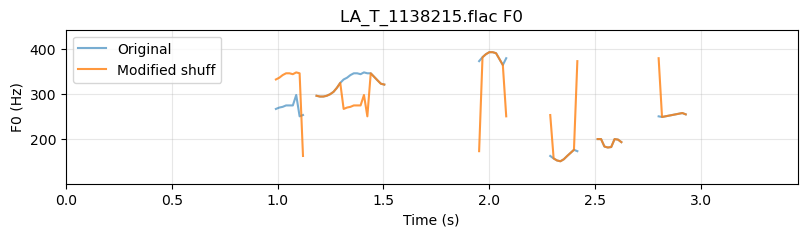

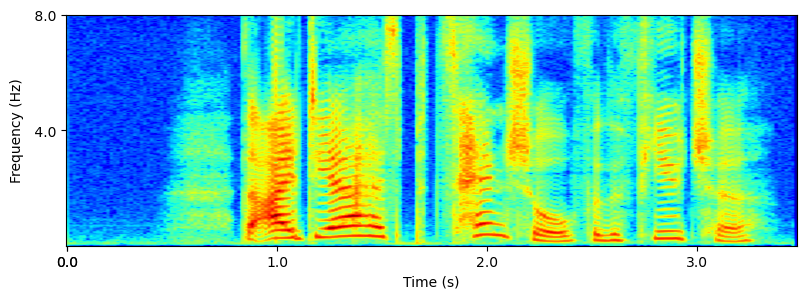

In [35]:
# plotting 
fig, axes = plt.subplots(1, 1, figsize=(9.44, 2), sharex=False)


n_frames = len(f0_traj)
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)

valid = np.isfinite(f0_traj)
f0_min = np.nanmin(f0_traj[valid])
f0_max = np.nanmax(f0_traj[valid])
pad = 50  # Hz for visualization

axes.plot(time, f0_traj, label="Original", alpha=0.6)
axes.plot(time, f0_traj_mod, label="Modified {:s}".format(mod), alpha=0.8)
axes.set_title(f"{str(filepath.name)} F0")
axes.set_ylim(f0_min - pad, f0_max + pad)
axes.set_xlim(0, max(time))
axes.legend()

axes.set_xlabel("Time (s)")
axes.set_ylabel("F0 (Hz)")
axes.grid(True, alpha=0.3)


display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig, axis = plt.subplots(1, 1, figsize=(9.44, 3), sharex=False)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size, 'frame_length': stft_params.win_size}})


### case study

Uing A04 tracks from ASVspoof2019

In [51]:
def feat_pipline(file_list, pipeline, feat_name, debug=False):
    
    rows = []
    total = len(file_list)
        
    for cnt, i in tqdm(enumerate(file_list), total=len(file_list)):
        x, sr = load_audio(i)
        feat = pipeline(x)
           
        rows.append({
            "name": str(i.name),
            "{:s}".format(feat_name): feat,
        })
    
        if debug and cnt > 9:
            break
    dataframe = pd.DataFrame(rows)
    return dataframe

In [52]:
def f0_mod_pipeline_shift(wav, stft_params=stft_params):
    
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )

    f0_traj_mod = apply_f0_mod(f0_traj, mod='shift', hop_s=stft_params.hop_sec)
    return f0_traj_mod

def f0_mod_pipeline_shuf(wav, stft_params=stft_params):
    
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )

    f0_traj_mod = apply_f0_mod(f0_traj, mod='shuff', hop_s=stft_params.hop_sec)
    return f0_traj_mod

def f0_mod_pipeline_nochange(wav, stft_params=stft_params):
    
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )

    return f0_traj

In [54]:
df_concat_tts = (
    df_all[df_all[3] == 'A04']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
fake_list = df_concat_tts['path'].tolist()


df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
real_list = df_real['path'].tolist()


fake_dataframe = feat_pipline(fake_list, f0_mod_pipeline_nochange, feat_name='f0', debug=True)
real_dataframe = feat_pipline(real_list, f0_mod_pipeline_nochange, feat_name='f0', debug=True)
mod_shift_dataframe = feat_pipline(real_list, f0_mod_pipeline_shift, feat_name='f0', debug=True)
mod_shuff_dataframe = feat_pipline(real_list, f0_mod_pipeline_shuf, feat_name='f0', debug=True)


  0%|▎                                                                        | 10/2580 [00:03<16:26,  2.60it/s]


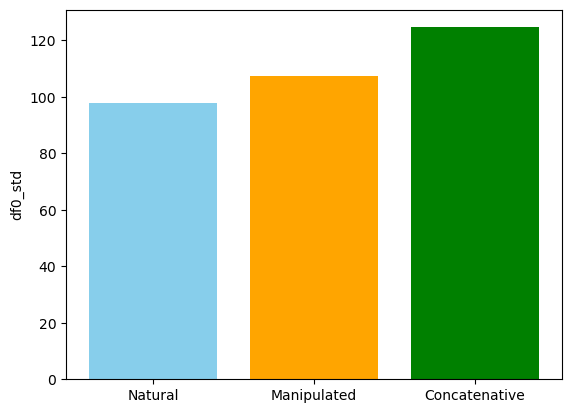

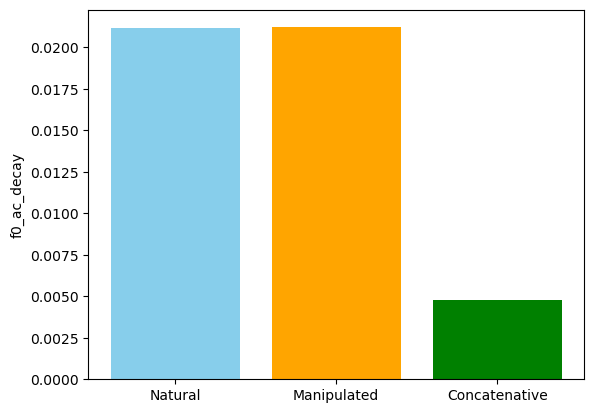

In [55]:
# ---------- support functions ----------
def autocorr_decay(x, max_lag=50):
    x = x - np.mean(x)
    ac = np.correlate(x, x, mode='full')
    ac = ac[len(ac)//2:]
    ac /= ac[0] + 1e-8
    return np.mean(ac[1:max_lag])

def f0_concat_features(f0, hop_s):
    f0 = np.asarray(f0, dtype=float)

    # voiced only
    voiced = ~np.isnan(f0)
    f0v = f0[voiced]
    if len(f0v) < 5:
        return None

    logf0 = 1200 * np.log2(f0v)  # convert Hz → cents
    dlogf0 = np.diff(logf0)

    feats = {}
    feats["df0_std"] = np.std(dlogf0)
    feats["f0_ac_decay"] = autocorr_decay(logf0)

    return feats

# ---------- corpus-level ----------
def corpus_f0_features(f0_list, hop_s):
    feats = []
    for f0 in f0_list:
        f = f0_concat_features(f0, hop_s)
        if f is not None:
            feats.append(f)
    return feats

def aggregate_features(feat_list):
    keys = feat_list[0].keys()
    agg = {}
    for k in keys:
        vals = np.array([f[k] for f in feat_list])
        agg[k + "_mean"] = np.mean(vals)
    return agg

# ---------- compute globals ----------
feat_nat_global = aggregate_features(
    corpus_f0_features(real_dataframe['f0'], stft_params.hop_sec)
)

feat_concat_global = aggregate_features(
    corpus_f0_features(mod_shift_dataframe['f0'], stft_params.hop_sec)
)

feat_fake_global = aggregate_features(
    corpus_f0_features(fake_dataframe['f0'], stft_params.hop_sec)
)

# ---------- plot ----------
keys_to_plot = ['df0_std', 'f0_ac_decay']

for k in keys_to_plot:
    plt.figure()
    plt.bar(
        ['Natural', 'Manipulated', 'Concatenative'],
        [feat_nat_global[k+'_mean'],
         feat_concat_global[k+'_mean'],
         feat_fake_global[k+'_mean']],
        color=['skyblue','orange','green']
    )
    plt.ylabel(k)
    plt.show()